# London Underground Visualizations
## Part 1: Base Map with Station Locations

This notebook builds up the tube map incrementally, starting with station locations.

In [17]:
import pyarrow.feather as feather
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Set up paths
DATA_DIR = Path('../data/processed_data')

# TfL line colors (official)
LINE_COLORS = {
    'BAK': '#B36305',  # Bakerloo - Brown
    'CEN': '#E32017',  # Central - Red
    'CIR': '#FFD300',  # Circle - Yellow
    'DIS': '#00782A',  # District - Green
    'HAM': '#F3A9BB',  # Hammersmith & City - Pink
    'JUB': '#A0A5A9',  # Jubilee - Grey
    'MET': '#9B0056',  # Metropolitan - Magenta
    'NTN': '#000000',  # Northern - Black
    'PIC': '#003688',  # Piccadilly - Dark Blue
    'VIC': '#0098D4',  # Victoria - Light Blue
    'WAC': '#95CDBA',  # Waterloo & City - Teal
}

LINE_NAMES = {
    'BAK': 'Bakerloo',
    'CEN': 'Central',
    'CIR': 'Circle',
    'DIS': 'District',
    'HAM': 'Hammersmith & City',
    'JUB': 'Jubilee',
    'MET': 'Metropolitan',
    'NTN': 'Northern',
    'PIC': 'Piccadilly',
    'VIC': 'Victoria',
    'WAC': 'Waterloo & City',
}

## Load and Transform Station Data

The data uses British National Grid (OSGB36) coordinates. We'll convert these to WGS84 (lat/lon) for mapping.

In [18]:
def osgb36_to_wgs84(easting, northing):
    """
    Convert British National Grid (OSGB36) to WGS84 lat/lon.
    Simplified conversion using pyproj if available, otherwise approximate formula.
    """
    try:
        from pyproj import Transformer
        transformer = Transformer.from_crs('EPSG:27700', 'EPSG:4326', always_xy=True)
        lon, lat = transformer.transform(easting, northing)
        return lat, lon
    except ImportError:
        # Approximate conversion for London area
        # This is a rough approximation - pyproj is more accurate
        lat = 49.0 + (northing / 111000)
        lon = -7.5 + (easting / (111000 * np.cos(np.radians(lat))))
        return lat, lon

# Load stop points
stops = feather.read_feather(DATA_DIR / 'ALL-StopPoints.feather')
print(f"Loaded {len(stops)} stations")
stops.head()

Loaded 691 stations


,AtcoCode,Descriptor_CommonName,Place_NptgLocalityRef,Place_Location_Easting,Place_Location_Northing,Latitude,Longitude,Zone
0,9400ZZLUWIM1,Wimbledon,E0034695,524793,170673,NaN,NaN,NaN
1,9400ZZLUWIP1,Wimbledon Park,E0034696,525266,172129,NaN,NaN,NaN
2,9400ZZLUSFS1,Southfields Station,E0034902,524715,173348,NaN,NaN,NaN
3,9400ZZLUEPY1,East Putney,N0077656,524371,174824,NaN,NaN,NaN
4,9400ZZLUPYB1,Putney Bridge,N0077709,524512,175890,NaN,NaN,NaN


In [19]:
# Convert coordinates
stops['Easting'] = pd.to_numeric(stops['Place_Location_Easting'])
stops['Northing'] = pd.to_numeric(stops['Place_Location_Northing'])

# Try to use pyproj for accurate conversion
try:
    from pyproj import Transformer
    transformer = Transformer.from_crs('EPSG:27700', 'EPSG:4326', always_xy=True)
    coords = transformer.transform(stops['Easting'].values, stops['Northing'].values)
    stops['Longitude'] = coords[0]
    stops['Latitude'] = coords[1]
    print("Used pyproj for accurate coordinate conversion")
except ImportError:
    print("pyproj not available, using approximate conversion")
    # Approximate conversion
    stops['Latitude'] = 49.0 + (stops['Northing'] / 111000)
    stops['Longitude'] = -7.5 + (stops['Easting'] / (111000 * np.cos(np.radians(stops['Latitude']))))

stops.head()

Used pyproj for accurate coordinate conversion


,AtcoCode,Descriptor_CommonName,Place_NptgLocalityRef,Place_Location_Easting,Place_Location_Northing,Latitude,Longitude,Zone,Easting,Northing
0,9400ZZLUWIM1,Wimbledon,E0034695,524793,170673,51.421341,-0.206625,NaN,524793,170673
1,9400ZZLUWIP1,Wimbledon Park,E0034696,525266,172129,51.434322,-0.199312,NaN,525266,172129
2,9400ZZLUSFS1,Southfields Station,E0034902,524715,173348,51.445399,-0.206805,NaN,524715,173348
3,9400ZZLUEPY1,East Putney,N0077656,524371,174824,51.458739,-0.211234,NaN,524371,174824
4,9400ZZLUPYB1,Putney Bridge,N0077709,524512,175890,51.468288,-0.208830,NaN,524512,175890


## Layer 1: Plot All Stations (Geographic View)

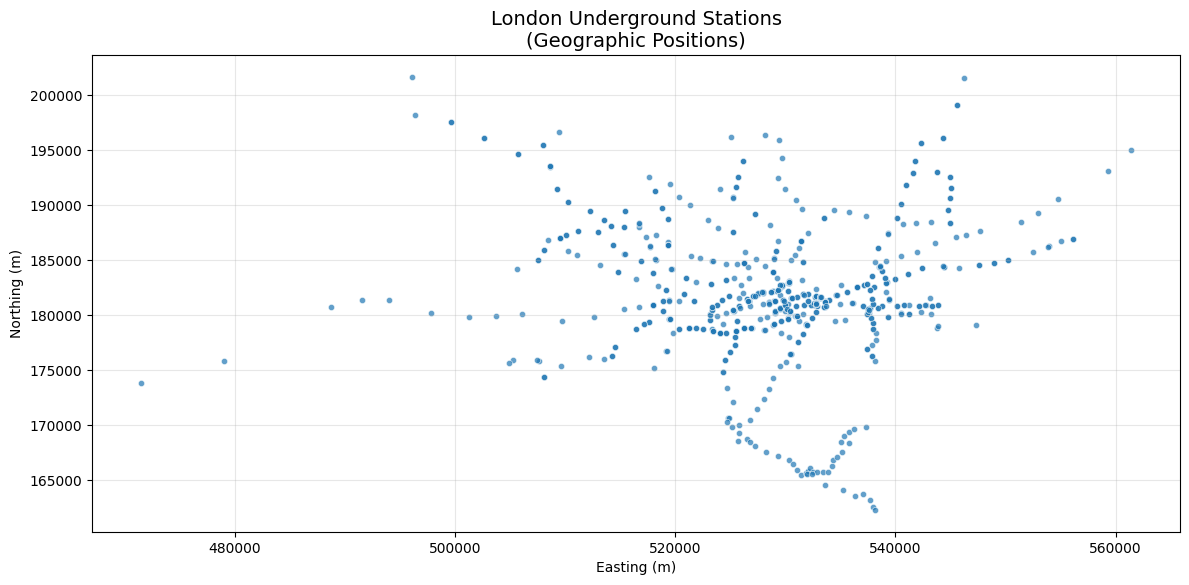

In [20]:
fig, ax = plt.subplots(figsize=(12, 14))

# Plot all stations
ax.scatter(stops['Easting'], stops['Northing'], 
           c='#1f77b4', s=20, alpha=0.7, edgecolors='white', linewidth=0.5)

ax.set_xlabel('Easting (m)')
ax.set_ylabel('Northing (m)')
ax.set_title('London Underground Stations\n(Geographic Positions)', fontsize=14)
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../output/01_stations_geographic.png', dpi=150, bbox_inches='tight')
plt.show()

## Layer 2: Load Route Links and Draw Lines

In [21]:
def load_route_links(line_code):
    """Load route links for a specific line."""
    path = DATA_DIR / f'{line_code}-RouteLinks.feather'
    if path.exists():
        return feather.read_feather(path)
    return None

def get_unique_edges(route_links):
    """Extract unique station-to-station edges from route links."""
    edges = route_links[['From_StopPointRef', 'To_StopPointRef']].drop_duplicates()
    return edges

# Create a lookup from AtcoCode to coordinates
stop_coords = stops.set_index('AtcoCode')[['Easting', 'Northing', 'Latitude', 'Longitude', 'Descriptor_CommonName']].to_dict('index')

# Load all route links
all_edges = {}
for line_code in LINE_COLORS.keys():
    links = load_route_links(line_code)
    if links is not None:
        edges = get_unique_edges(links)
        all_edges[line_code] = edges
        print(f"{line_code}: {len(edges)} unique edges")

BAK: 48 unique edges
CEN: 98 unique edges
CIR: 120 unique edges
DIS: 122 unique edges
HAM: 74 unique edges
JUB: 53 unique edges
MET: 74 unique edges
NTN: 106 unique edges
PIC: 115 unique edges
VIC: 30 unique edges
WAC: 2 unique edges


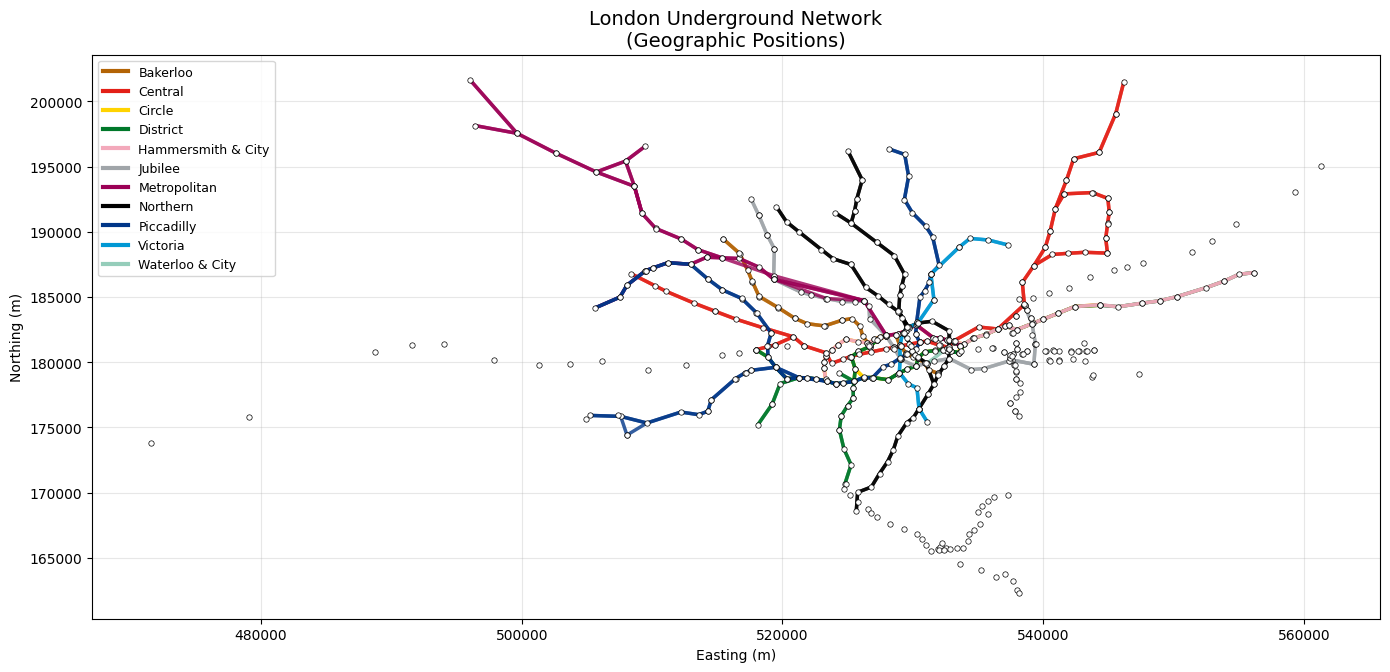

In [22]:
def plot_line(ax, line_code, edges, stop_coords, color, linewidth=2, alpha=0.8):
    """Plot a single tube line on the axes."""
    for _, edge in edges.iterrows():
        from_stop = edge['From_StopPointRef']
        to_stop = edge['To_StopPointRef']
        
        if from_stop in stop_coords and to_stop in stop_coords:
            x = [stop_coords[from_stop]['Easting'], stop_coords[to_stop]['Easting']]
            y = [stop_coords[from_stop]['Northing'], stop_coords[to_stop]['Northing']]
            ax.plot(x, y, color=color, linewidth=linewidth, alpha=alpha, solid_capstyle='round')

# Plot all lines
fig, ax = plt.subplots(figsize=(14, 16))

# Draw lines first
for line_code, edges in all_edges.items():
    plot_line(ax, line_code, edges, stop_coords, LINE_COLORS[line_code], linewidth=2.5, alpha=0.8)

# Draw stations on top
ax.scatter(stops['Easting'], stops['Northing'], 
           c='white', s=15, edgecolors='black', linewidth=0.5, zorder=10)

ax.set_xlabel('Easting (m)')
ax.set_ylabel('Northing (m)')
ax.set_title('London Underground Network\n(Geographic Positions)', fontsize=14)
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)

# Add legend
from matplotlib.lines import Line2D
legend_elements = [Line2D([0], [0], color=color, linewidth=3, label=LINE_NAMES.get(code, code))
                   for code, color in LINE_COLORS.items() if code in all_edges]
ax.legend(handles=legend_elements, loc='upper left', fontsize=9)

plt.tight_layout()
plt.savefig('../output/02_network_geographic.png', dpi=150, bbox_inches='tight')
plt.show()

## Layer 3: Individual Line Maps

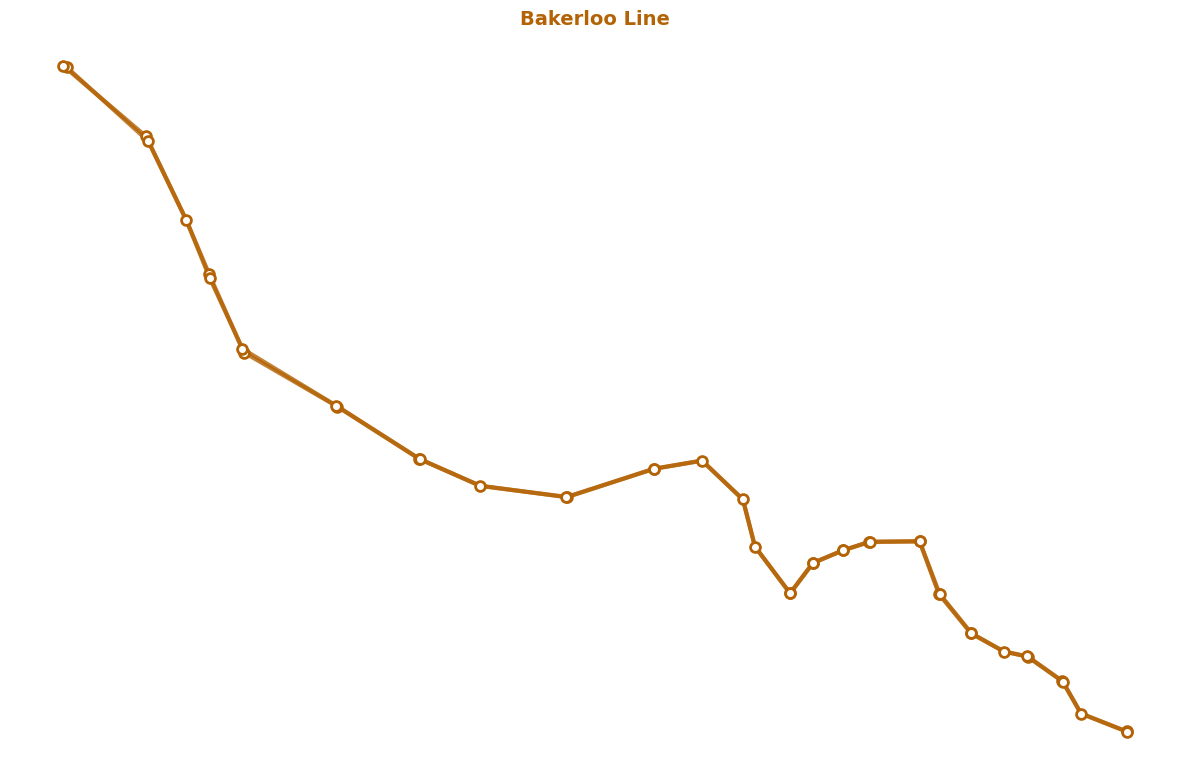

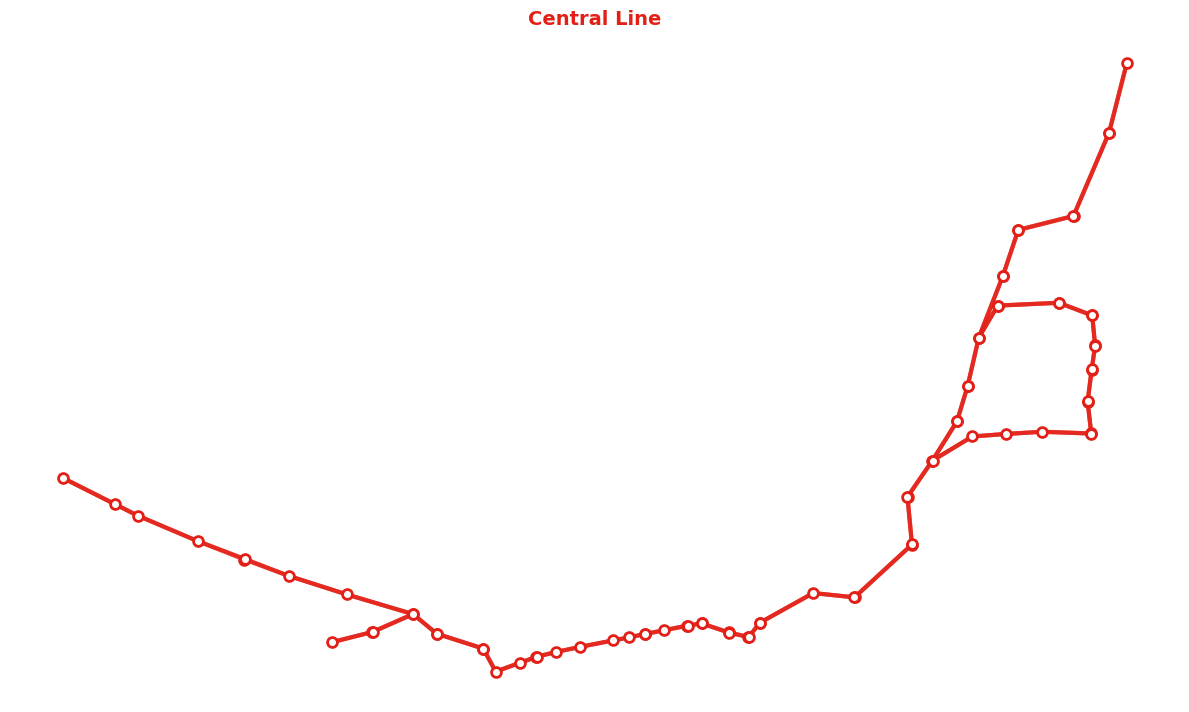

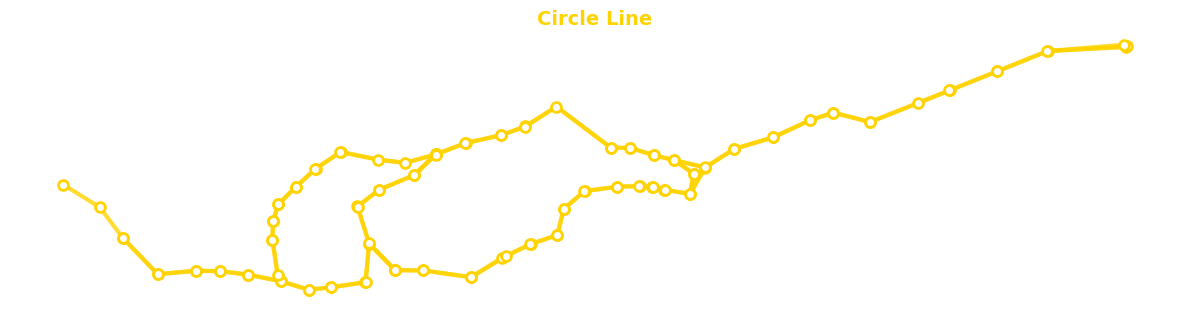

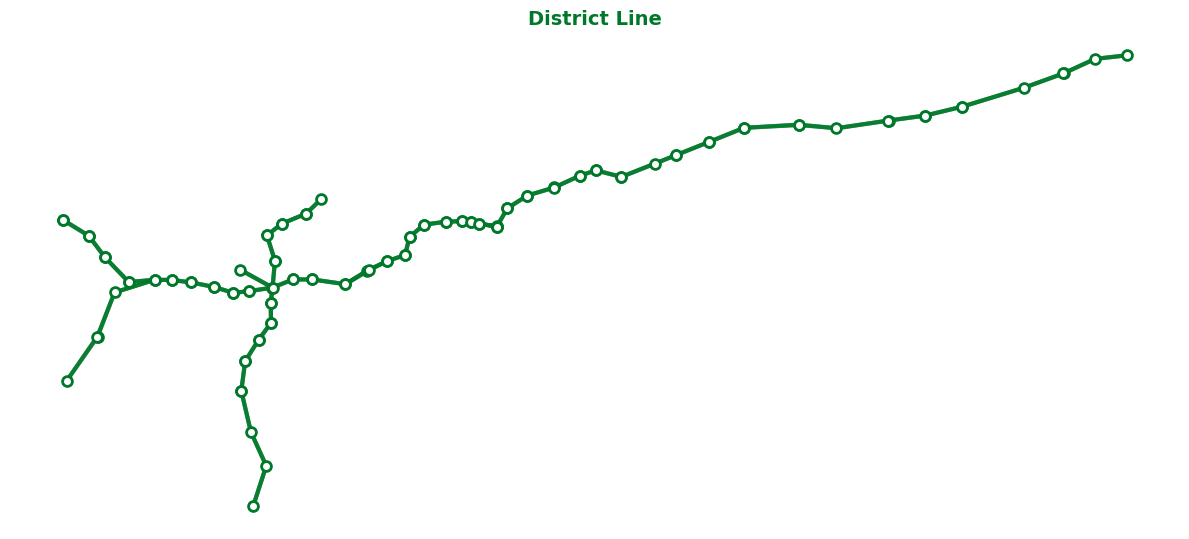

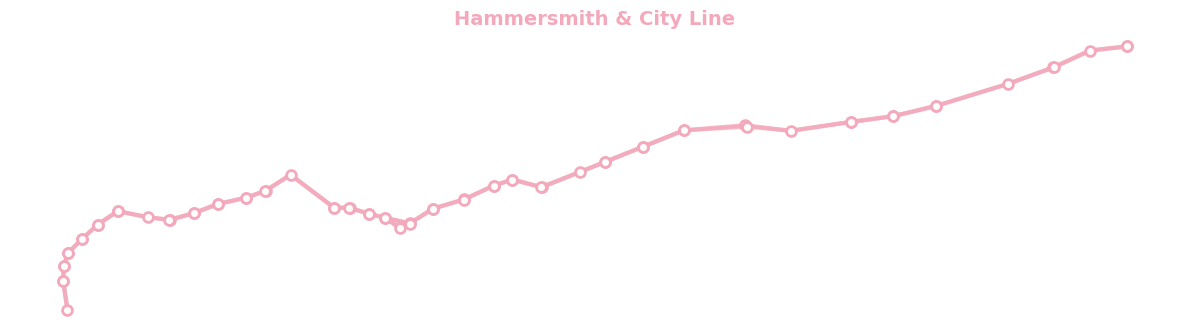

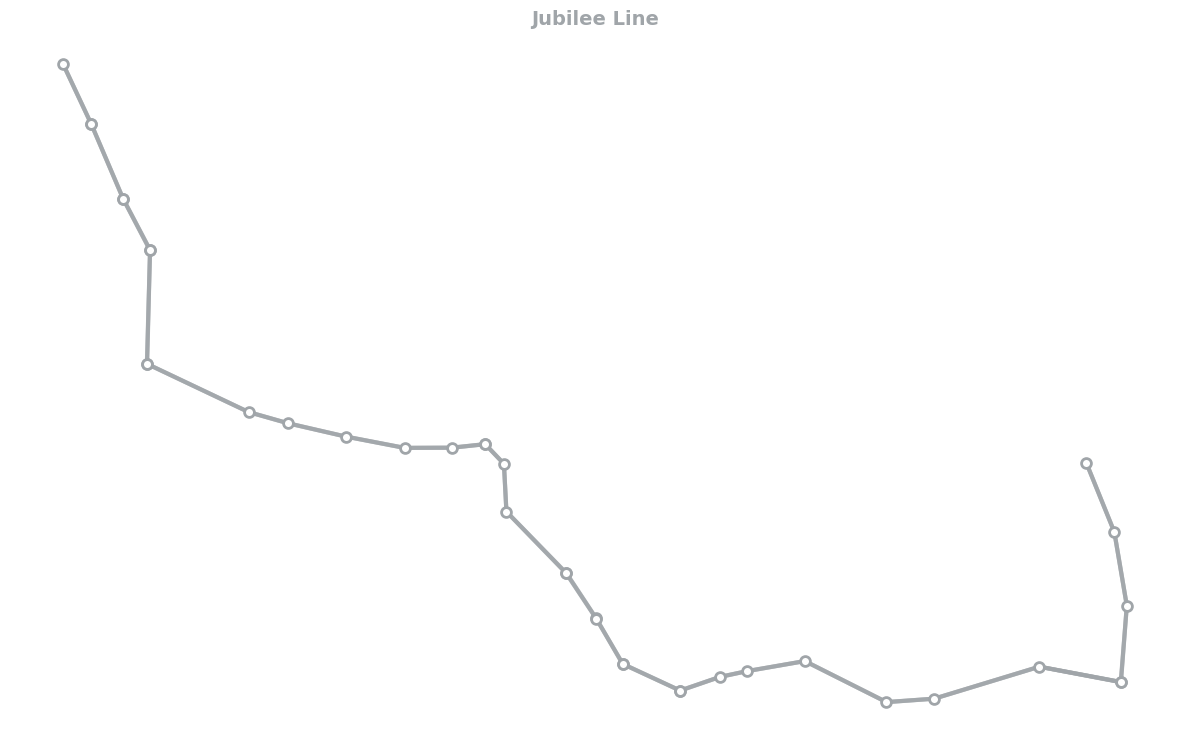

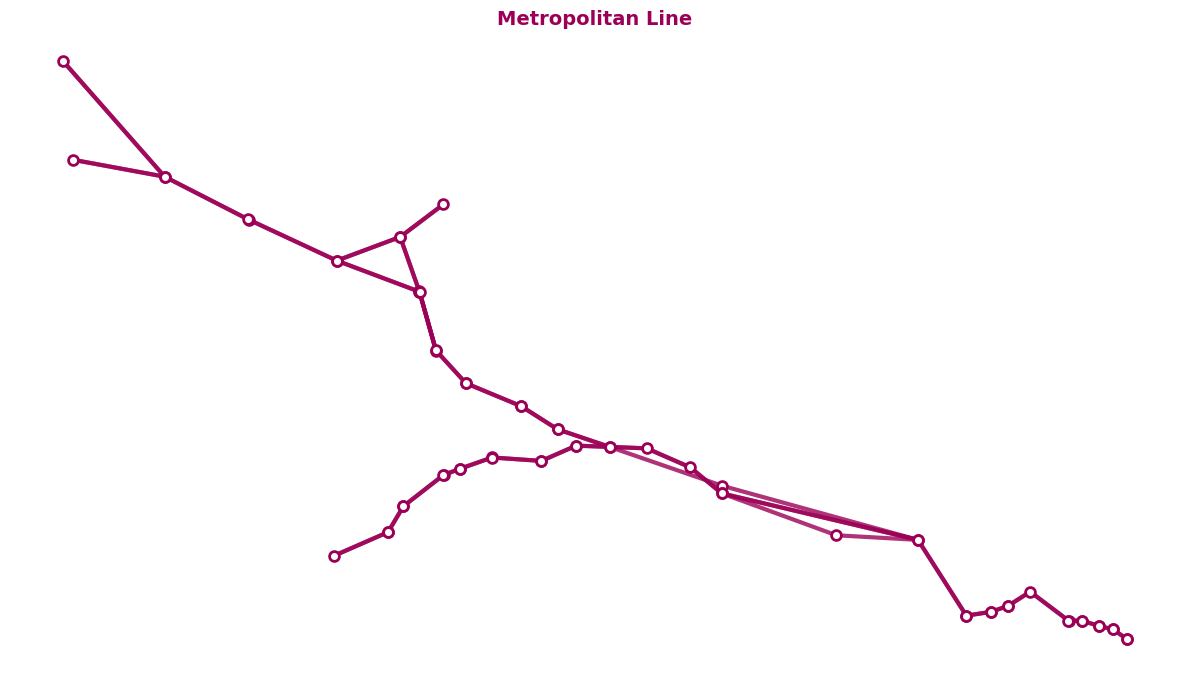

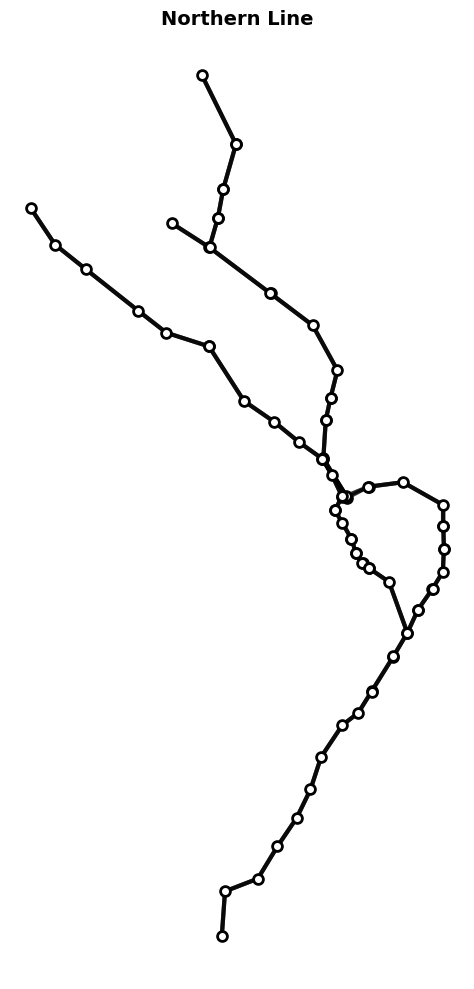

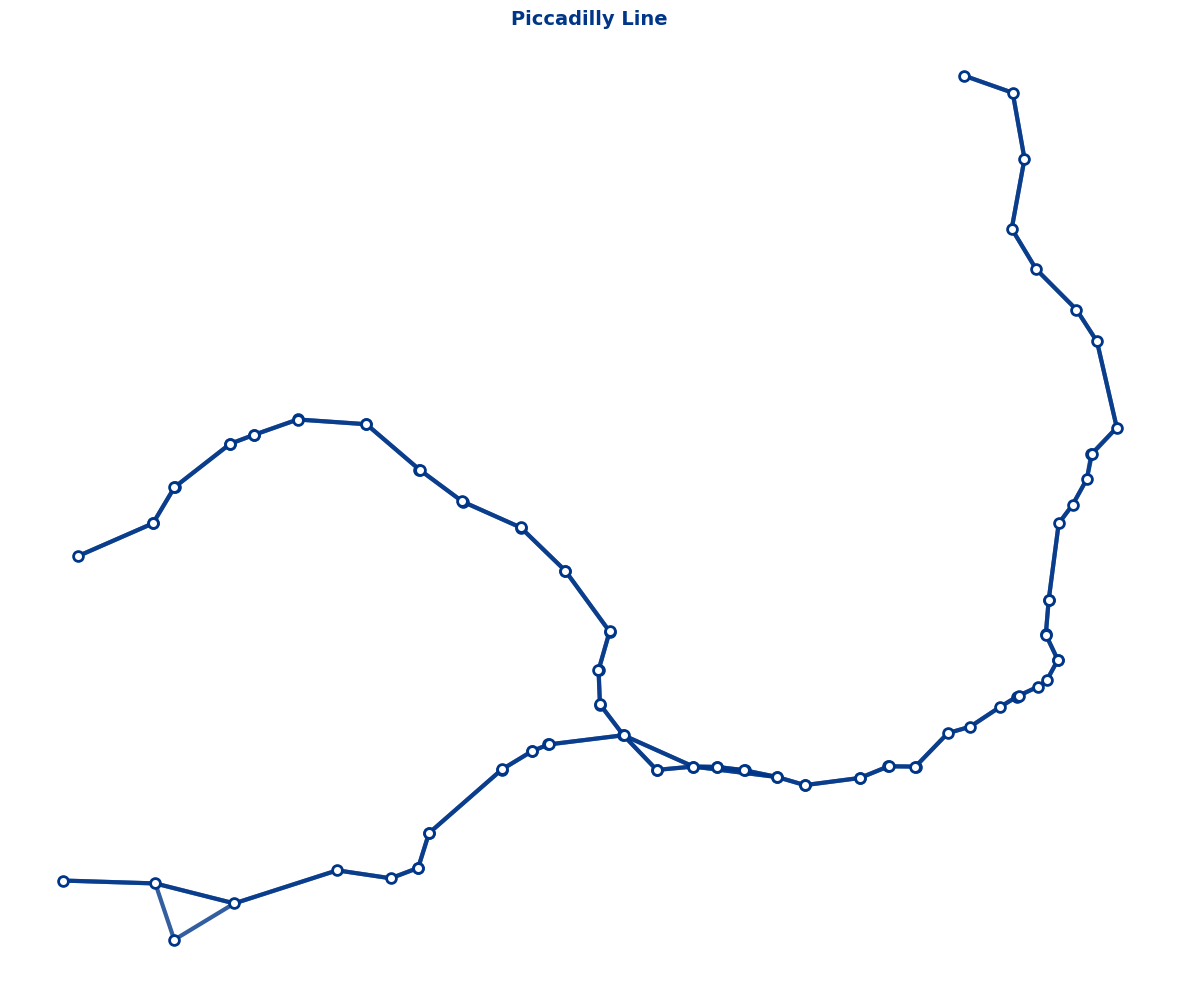

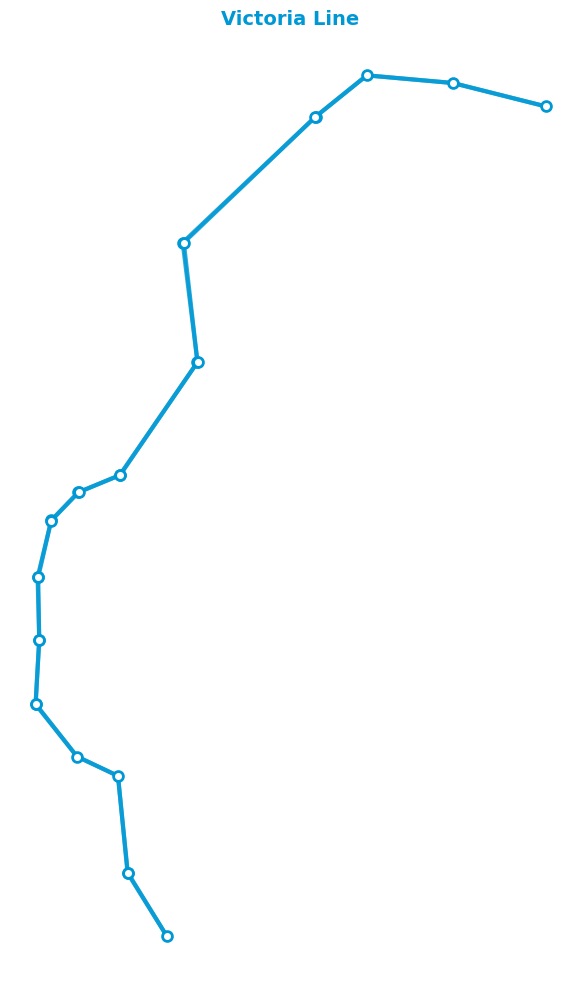

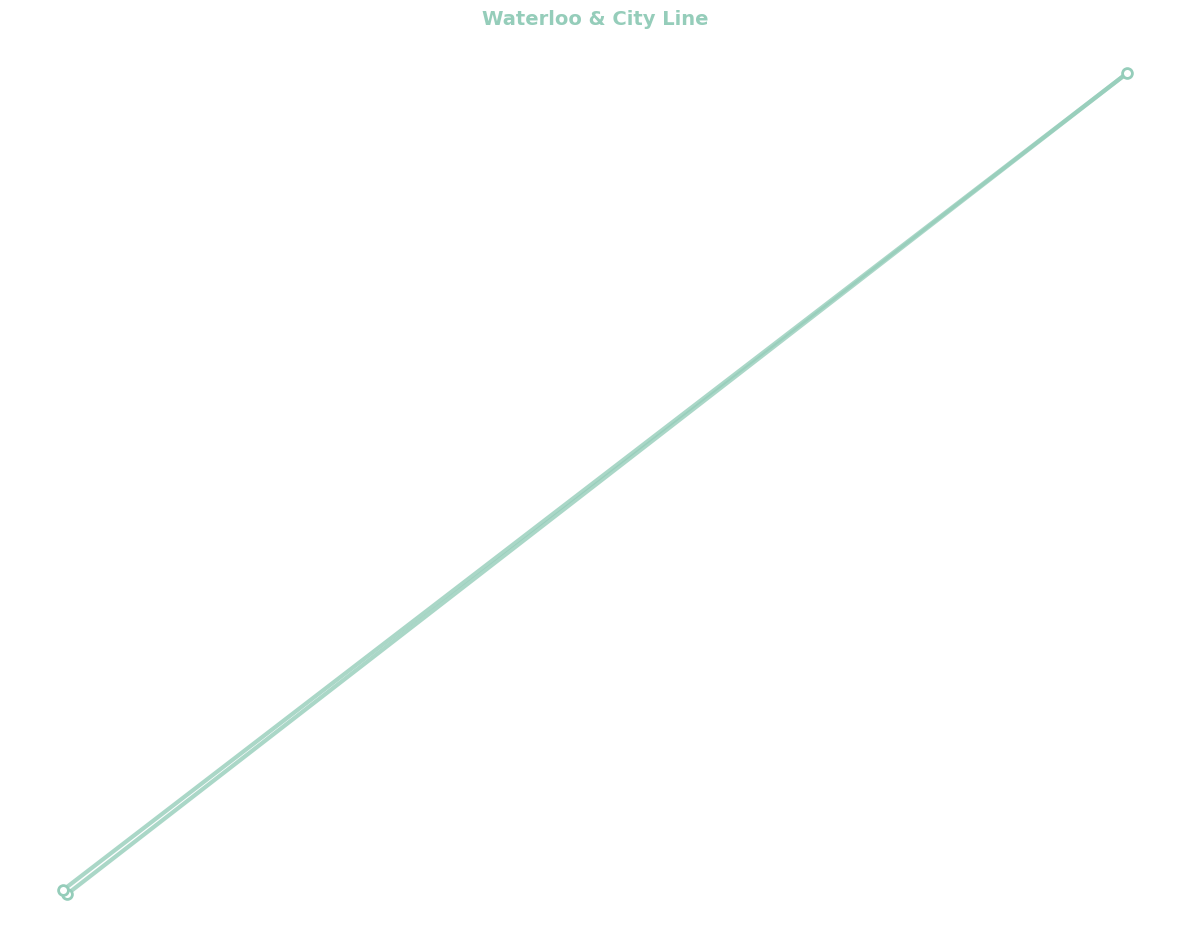

In [23]:
def plot_single_line(line_code, edges, stop_coords, color, title):
    """Create a map for a single tube line."""
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # Get stations on this line
    line_stations = set(edges['From_StopPointRef'].tolist() + edges['To_StopPointRef'].tolist())
    
    # Draw edges
    plot_line(ax, line_code, edges, stop_coords, color, linewidth=3)
    
    # Draw stations
    for station in line_stations:
        if station in stop_coords:
            ax.scatter(stop_coords[station]['Easting'], stop_coords[station]['Northing'],
                      c='white', s=50, edgecolors=color, linewidth=2, zorder=10)
    
    ax.set_title(title, fontsize=14, color=color, fontweight='bold')
    ax.set_aspect('equal')
    ax.axis('off')
    
    return fig, ax

# Plot each line individually
for line_code, edges in all_edges.items():
    fig, ax = plot_single_line(line_code, edges, stop_coords, 
                               LINE_COLORS[line_code], 
                               f"{LINE_NAMES.get(line_code, line_code)} Line")
    plt.tight_layout()
    plt.savefig(f'../output/line_{line_code.lower()}.png', dpi=150, bbox_inches='tight', 
                facecolor='white', edgecolor='none')
    plt.show()

## Layer 4: Incremental Build-up Animation Data

Create data for animating the network being built line by line.

In [ ]:
# Order lines by historical opening (approximate)
LINE_ORDER = ['MET', 'DIS', 'CIR', 'NTN', 'BAK', 'PIC', 'CEN', 'VIC', 'JUB', 'HAM', 'WAC']

def create_incremental_frames():
    """Create frames showing the network being built up line by line."""
    frames = []
    current_edges = {}
    
    for line_code in LINE_ORDER:
        if line_code in all_edges:
            current_edges[line_code] = all_edges[line_code]
            
            fig, ax = plt.subplots(figsize=(14, 16))
            
            # Draw all lines added so far
            for code, edges in current_edges.items():
                plot_line(ax, code, edges, stop_coords, LINE_COLORS[code], linewidth=2.5)
            
            # Collect all stations
            all_stations = set()
            for edges in current_edges.values():
                all_stations.update(edges['From_StopPointRef'].tolist())
                all_stations.update(edges['To_StopPointRef'].tolist())
            
            # Draw stations
            for station in all_stations:
                if station in stop_coords:
                    ax.scatter(stop_coords[station]['Easting'], stop_coords[station]['Northing'],
                              c='white', s=15, edgecolors='black', linewidth=0.5, zorder=10)
            
            ax.set_title(f'London Underground Network\n(Added: {LINE_NAMES.get(line_code, line_code)} Line)', 
                        fontsize=14)
            ax.set_aspect('equal')
            ax.axis('off')
            
            # Add legend showing which lines are included
            legend_elements = [Line2D([0], [0], color=LINE_COLORS[c], linewidth=3, label=LINE_NAMES.get(c, c))
                               for c in current_edges.keys()]
            ax.legend(handles=legend_elements, loc='upper left', fontsize=9)
            
            plt.tight_layout()
            plt.savefig(f'../output/incremental_{len(current_edges):02d}_{line_code}.png', 
                       dpi=150, bbox_inches='tight')
            plt.close()
            
            frames.append(line_code)
    
    return frames

frames = create_incremental_frames()
print(f"Created {len(frames)} incremental frames")